# Validating the basic LRIS-2 ETC math

This notebook works through the basic calculations behind the ETC by hand:

1. Photons s$^{-1}$ Å$^{-1}$ collected by Keck I from a source of a given AB magnitude, and from the Mauna Kea night sky.
2. The LRIS-2 B600 and R400 efficiency, including the atmosphere at airmass 1.2, and its average over each filter.

The filters are SDSS u'g'r'i' and **LSST z** in place of SDSS z'. The SDSS z' curve runs to 13500 Å, past the end of both the R400 grating (10000 Å) and the sky spectrum (9993 Å), and its effective wavelength (10931 Å) lies outside both. LSST z (half maximum 8175–9249 Å, $\lambda_{\rm eff} \approx 8703$ Å) lies entirely inside them. The z sky is 19.4 mag arcsec$^{-2}$ in LSST z, the same filter the ETC's `Sky.scale_to_mags` matches. The LSST filter files give wavelength in nm, and `Mag` converts them to Å.
3. The SNR of an $m_{AB}=22$ source in a square aperture that holds 50% of its light, as a function of the aperture area.

Every step is written out, and the package is only used to read the data files.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

from lris2_etc import Mag, Sky, Telescope, Instrument, Transmission, Moffat

%matplotlib inline

## 1. Photon rates from AB magnitudes

The AB magnitude defines the flux density per unit frequency:

$$f_\nu = 10^{-0.4\,(m_{AB} + 48.60)}\ \ \mathrm{erg\,s^{-1}\,cm^{-2}\,Hz^{-1}}$$

Converting to per unit wavelength, with $c$ in Å s$^{-1}$:

$$f_\lambda = f_\nu\,\frac{c}{\lambda^2}\ \ \mathrm{erg\,s^{-1}\,cm^{-2}\,\AA^{-1}}$$

Dividing by the energy per photon, $hc/\lambda$:

$$n_\lambda = \frac{f_\lambda}{hc/\lambda} = \frac{f_\nu}{h\,\lambda}\ \ \mathrm{photons\,s^{-1}\,cm^{-2}\,\AA^{-1}}$$

and multiplying by the Keck I collecting area $A$:

$$N_\lambda = n_\lambda\,A\ \ \mathrm{photons\,s^{-1}\,\AA^{-1}}$$

For the sky, $m_{AB}$ is a surface brightness in mag arcsec$^{-2}$, so $N_\lambda$ is per arcsec$^2$.

Each band is evaluated at its effective wavelength, $\lambda_{\rm eff} = \int \lambda F\,d\lambda / \int F\,d\lambda$, as computed by `Mag`. These photon rates are at the top of the atmosphere for the source and at the ground for the sky. No efficiency has been applied yet.

In [4]:
h = 6.62607015e-27      # erg s
c = 2.99792458e18       # Angstrom / s

tel = Telescope.Telescope(name='keck1')
A = tel.area            # cm^2
print(f'Keck I collecting area A = {A:.0f} cm^2 (10 m primary with 7.9% central obscuration)')

bands = ['u', 'g', 'r', 'i', 'z']
filters = {b: Mag.Mag(f'sdss_{b}prime') for b in ['u', 'g', 'r', 'i']}
# LSST z in place of SDSS z'; Mag converts the LSST file from nm to Angstroms
filters['z'] = Mag.Mag('LSST_LSST.z')
label = {'u': "u'", 'g': "g'", 'r': "r'", 'i': "i'", 'z': 'z (LSST)'}

# Mauna Kea dark sky, AB mag / arcsec^2 (z is LSST z)
sky_mag = {'u': 22.9, 'g': 22.0, 'r': 21.4, 'i': 20.4, 'z': 19.4}
src_mag = 21.0

def photon_rate(m_ab, lam):
    '''photons / s / Angstrom collected by Keck I for AB magnitude m_ab at wavelength lam (Angstrom)'''
    f_nu = 10**(-0.4*(m_ab + 48.60))     # erg / s / cm^2 / Hz
    f_lam = f_nu * c / lam**2            # erg / s / cm^2 / A
    n_lam = f_lam / (h * c / lam)        # photons / s / cm^2 / A
    return n_lam * A                     # photons / s / A

Keck I collecting area A = 723674 cm^2 (10 m primary with 7.9% central obscuration)


A worked example in r', step by step:

In [5]:
lam = filters['r'].lambda_eff
f_nu = 10**(-0.4*(src_mag + 48.60))
f_lam = f_nu * c / lam**2
e_ph = h * c / lam
n_lam = f_lam / e_ph
print(f"lambda_eff(r')  = {lam:.1f} A")
print(f'f_nu            = 10^(-0.4 ({src_mag} + 48.60))         = {f_nu:.4e} erg/s/cm^2/Hz')
print(f'f_lambda        = f_nu c / lambda^2                  = {f_lam:.4e} erg/s/cm^2/A')
print(f'E_photon        = h c / lambda                       = {e_ph:.4e} erg')
print(f'n_lambda        = f_lambda / E_photon                = {n_lam:.4e} photons/s/cm^2/A')
print(f'N_lambda        = n_lambda x {A:.0f} cm^2           = {n_lam*A:.3f} photons/s/A')

lambda_eff(r')  = 6260.4 A
f_nu            = 10^(-0.4 (21.0 + 48.60))         = 1.4454e-28 erg/s/cm^2/Hz
f_lambda        = f_nu c / lambda^2                  = 1.1056e-17 erg/s/cm^2/A
E_photon        = h c / lambda                       = 3.1730e-12 erg
n_lambda        = f_lambda / E_photon                = 3.4845e-06 photons/s/cm^2/A
N_lambda        = n_lambda x 723674 cm^2           = 2.522 photons/s/A


In [6]:
mstr = f'source m={src_mag}'
print(f"{'band':4} {'lam_eff':>8} {mstr:>12} {'sky m':>6} {'sky':>12}")
print(f"{'':4} {'(A)':>8} {'(ph/s/A)':>12} {'':>6} {'(ph/s/A/as2)':>12}")
src_rate, sky_rate = {}, {}
for b in bands:
    lam = filters[b].lambda_eff
    src_rate[b] = photon_rate(src_mag, lam)
    sky_rate[b] = photon_rate(sky_mag[b], lam)
    print(f'{b:4} {lam:8.1f} {src_rate[b]:12.3f} {sky_mag[b]:6.1f} {sky_rate[b]:12.3f}')

band  lam_eff source m=21.0  sky m          sky
          (A)     (ph/s/A)        (ph/s/A/as2)
u      3506.5        4.502   22.9        0.782
g      4782.3        3.301   22.0        1.314
r      6260.4        2.522   21.4        1.745
i      7732.0        2.042   20.4        3.548
z      8702.9        1.814   19.4        7.918


### Cross-checks against the package

1. `Mag.compute_ABmag` should return 22.0 for a spectrum with constant $f_\nu$ at $m_{AB}=22$. It averages $f_\lambda$ over the filter and converts with $\lambda_{\rm eff}^2/c$, which is an approximation, so small differences are expected.
2. The ETC's sky spectrum (`Sky()`, after `scale_to_mags`) is in photons s$^{-1}$ Å$^{-1}$ arcsec$^{-2}$ for the Keck I area, before any throughput. Its filter-weighted mean, $\int S F\,d\lambda / \int F\,d\lambda$, should be close to the table-based rate above. It won't match exactly: the sky has lines, and the rescaling is interpolated between filters.

In [7]:
wave = np.arange(3000., 11001., 1.)
flat_flam = 10**(-0.4*(src_mag + 48.60)) * c / wave**2
sky = Sky.Sky()

print(f"{'band':4} {'compute_ABmag':>13} {'table sky':>10} {'ETC sky':>9} {'ratio':>6}")
for b in bands:
    filt = filters[b]
    m_check = filt.compute_ABmag(wave, flat_flam)
    weight = np.interp(sky.wave, filt.wave, filt.weight, left=0, right=0)
    etc_sky = np.trapezoid(sky.spec * weight, sky.wave) / np.trapezoid(weight, sky.wave)
    print(f'{b:4} {m_check:13.3f} {sky_rate[b]:10.3f} {etc_sky:9.3f} {etc_sky/sky_rate[b]:6.2f}')

band compute_ABmag  table sky   ETC sky  ratio
u           20.992      0.782     0.785   1.00
g           20.974      1.314     1.287   0.98
r           20.987      1.745     1.811   1.04
i           20.988      3.548     3.953   1.11
z           20.995      7.918     7.680   0.97


## 2. Efficiency, including the atmosphere

The LRIS-2 efficiency is the product of the component curves:

$$E_{\rm inst}(\lambda) = \underbrace{M_1\,M_2\,\mathrm{ADC}}_{\rm Keck\ I}\ \times\ \underbrace{\mathrm{Window}\cdot\mathrm{COLL\text{-}M1}\cdot\mathrm{COLL\text{-}M2}\cdot\mathrm{DICHROIC}\cdot\mathrm{FOLD}\cdot\mathrm{CAMERA}}_{\rm common\ path}\ \times\ \underbrace{\mathrm{DE}\cdot\mathrm{PRISMS}}_{\rm grating}\ \times\ \mathrm{QE}$$

The atmospheric transmission at airmass $X$, from the extinction curve $k(\lambda)$ in mag airmass$^{-1}$ (`Transmission`), is

$$T_{\rm atm}(\lambda) = 10^{-0.4\,k(\lambda)\,X}, \qquad X = 1.2$$

and the total efficiency for the source is $E_{\rm tot} = E_{\rm inst}\,T_{\rm atm}$.

Each curve is read with `Instrument.read_efficiency_file`, as the ETC does: a cubic spline inside the data, continued linearly beyond it, and clipped to [0, 1]. The grid is cut at the edges of each grating efficiency file: B600 3100–5600 Å and R400 5500–10000 Å. The ETC itself uses slightly different cutoffs, B600 to 5700 Å (extrapolated) and R400 to 9500 Å.

In [8]:
airmass = 1.2
trans = Transmission.Transmission(airmass=airmass)

arms = {}
for grating, config in [('B600', 'lris2_blue'), ('R400', 'lris2_red')]:
    inst = Instrument.Instrument()
    getattr(inst, config)(tel, grating=grating)
    gfile = os.path.join(inst.throughput_dir, f'{grating}_grating.csv')
    gwave = np.genfromtxt(gfile, delimiter=',', names=True)['wavelength'] * 10   # nm -> A
    wave = np.arange(gwave.min(), gwave.max() + 1, 10.)

    components = {}
    for fn in [tel.throughput_file, inst.common_path_file, f'{grating}_grating.csv']:
        components.update(inst.read_efficiency_file(fn, wave))
    components['QE'] = next(iter(inst.read_efficiency_file(inst.detector_qe_file, wave).values()))

    e_inst = np.ones_like(wave)
    for eff in components.values():
        e_inst *= eff
    t_atm = np.interp(wave, trans.wave, trans.extinct)

    arms[grating] = dict(inst=inst, wave=wave, components=components,
                         e_inst=e_inst, t_atm=t_atm, e_tot=e_inst * t_atm)
    print(f'{grating}: {wave.min():.0f}-{wave.max():.0f} A, E_inst = ' + ' x '.join(components))

    # check against the ETC's own product on the wavelengths both cover
    inst.read_throughput()
    etc = inst.throughput
    sel = (wave >= etc['wavelength'].min()) & (wave <= etc['wavelength'].max())
    diff = np.abs(np.interp(wave[sel], etc['wavelength'], etc['throughput']) - e_inst[sel]).max()
    print(f'      max |E_inst - Instrument.read_throughput| = {diff:.2e}')

B600: 3100-5600 A, E_inst = TELE-M1 x TELE-M2 x ADC x Window x COLL-M1 x COLL-M2 x DICHROIC x FOLD x CAMERA x DE x PRISMS x QE
      max |E_inst - Instrument.read_throughput| = 2.22e-16
R400: 5500-10000 A, E_inst = TELE-M1 x TELE-M2 x ADC x Window x COLL-M1 x COLL-M2 x DICHROIC x FOLD x CAMERA x DE x PRISMS x QE
      max |E_inst - Instrument.read_throughput| = 2.78e-16


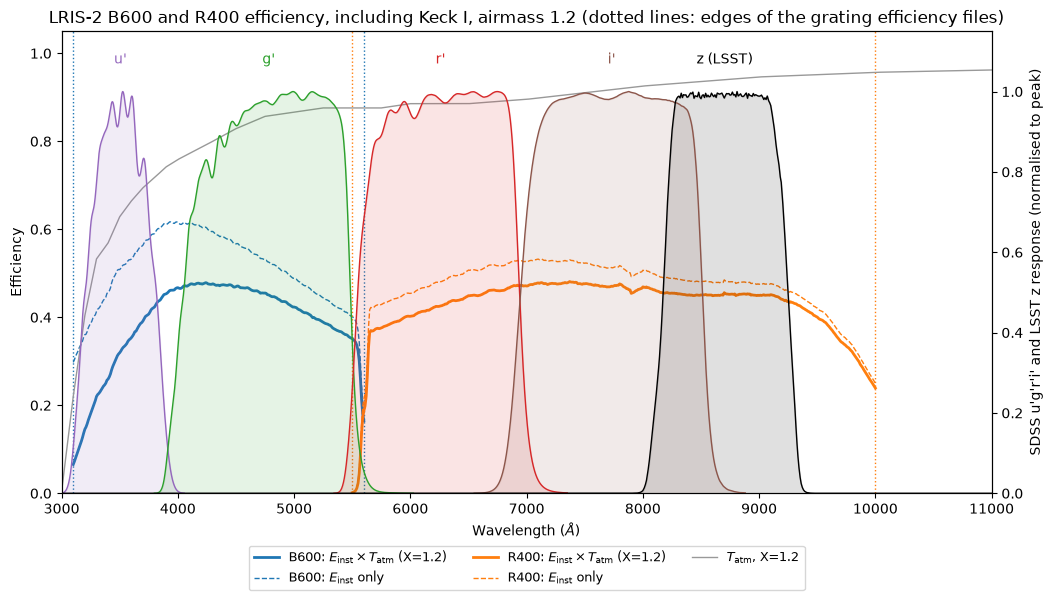

In [11]:
colors = {'u': 'tab:purple', 'g': 'tab:green', 'r': 'tab:red', 'i': 'tab:brown', 'z': 'k'}
fig, ax = plt.subplots(figsize=(12, 6))
for grating, arm in arms.items():
    col = 'tab:blue' if grating == 'B600' else 'tab:orange'
    ax.plot(arm['wave'], arm['e_tot'], '-', color=col, lw=2,
            label=f'{grating}: $E_{{\\rm inst}} \\times T_{{\\rm atm}}$ (X={airmass})')
    ax.plot(arm['wave'], arm['e_inst'], '--', color=col, lw=1, label=f'{grating}: $E_{{\\rm inst}}$ only')
    for edge in (arm['wave'].min(), arm['wave'].max()):
        ax.axvline(edge, color=col, ls=':', lw=1)
wave_atm = np.arange(3000, 11001, 10.)
ax.plot(wave_atm, np.interp(wave_atm, trans.wave, trans.extinct), color='0.6', lw=1,
        label=f'$T_{{\\rm atm}}$, X={airmass}')
ax.set_xlabel(r'Wavelength ($\AA$)')
ax.set_ylabel('Efficiency')
ax.set_xlim(3000, 11000)
ax.set_ylim(0, 1.05)

ax2 = ax.twinx()
for b in bands:
    filt = filters[b]
    ax2.fill_between(filt.wave, filt.weight / filt.weight.max(), color=colors[b], alpha=0.12)
    ax2.plot(filt.wave, filt.weight / filt.weight.max(), color=colors[b], lw=1)
    ax2.text(filt.lambda_eff, 1.07, label[b], color=colors[b], ha='center')
ax2.set_ylabel("SDSS u'g'r'i' and LSST z response (normalised to peak)")
ax2.set_ylim(0, 1.15)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=9)
ax.set_title('LRIS-2 B600 and R400 efficiency, including Keck I, airmass 1.2 '
             '(dotted lines: edges of the grating efficiency files)')
plt.show()

### Average efficiency in each filter

For filter response $F(\lambda)$ and an arm covering $[\lambda_1, \lambda_2]$ (the grating file edges), the filter-weighted average is

$$\langle E \rangle = \frac{\int_{\lambda_1}^{\lambda_2} E(\lambda)\,F(\lambda)\,d\lambda}{\int_{\lambda_1}^{\lambda_2} F(\lambda)\,d\lambda}$$

and the fraction of the filter that the arm covers is

$$\mathrm{coverage} = \frac{\int_{\lambda_1}^{\lambda_2} F\,d\lambda}{\int F\,d\lambda}.$$

$\langle E_{\rm tot}\rangle$ includes the atmosphere and applies to the source. $\langle E_{\rm inst}\rangle$ leaves the atmosphere out and applies to the sky, which is emitted in the atmosphere and is already a ground-level brightness.

In [12]:
avg = {}
print(f"{'band':4} {'arm':5} {'coverage':>8} {'<E_tot>':>8} {'<E_inst>':>8}")
for b in bands:
    filt = filters[b]
    full = np.trapezoid(filt.weight, filt.wave)
    for grating, arm in arms.items():
        weight = np.interp(arm['wave'], filt.wave, filt.weight, left=0, right=0)
        covered = np.trapezoid(weight, arm['wave'])
        if covered / full < 0.005:   # skip arms that see less than 0.5% of the filter
            continue
        e_tot = np.trapezoid(arm['e_tot'] * weight, arm['wave']) / covered
        e_inst = np.trapezoid(arm['e_inst'] * weight, arm['wave']) / covered
        avg[(b, grating)] = dict(coverage=covered / full, e_tot=e_tot, e_inst=e_inst)
        print(f'{b:4} {grating:5} {covered/full:8.2f} {e_tot:8.3f} {e_inst:8.3f}')

band arm   coverage  <E_tot> <E_inst>
u    B600      0.99    0.307    0.495
g    B600      1.00    0.435    0.519
g    R400      0.01    0.069    0.079
r    B600      0.04    0.290    0.331
r    R400      0.99    0.410    0.463
i    R400      1.00    0.467    0.510
z    R400      1.00    0.451    0.479


## 3. SNR against the area of the 50% square

Take a square aperture of side $s$ (arcsec) that holds 50% of the source's light. Spectroscopically, this is a slit of width $s$ with an extraction of length $s$ along the slit. The total source light is then that of $m_{AB}=22$, of which half, equivalent to $22 + 2.5\log_{10}2 = 22.75$, lands in the aperture. Better seeing makes the 50% square smaller, so it holds less sky and fewer detector pixels.

Per Å of spectrum, in an exposure of $t$ seconds:

| term | expression |
|---|---|
| source | $S = \tfrac{1}{2}\,N_\lambda^{\rm src}\,\langle E_{\rm tot}\rangle\,t$ |
| sky | $B = N_\lambda^{\rm sky}\,s^2\,\langle E_{\rm inst}\rangle\,t$ |
| detector | $D = \dfrac{s}{p}\,\dfrac{1}{\Delta\lambda_{\rm pix}}\,(\sigma_{\rm RN}^2 + d\,t)$ |
| SNR per Å | $S/\sqrt{S + B + D}$ |

Here $p$ is the spatial pixel scale, $\Delta\lambda_{\rm pix}$ the Å per pixel, $\sigma_{\rm RN}$ the read noise and $d$ the dark current, all from `Instrument`. $(s/p)/\Delta\lambda_{\rm pix}$ is the number of pixels per Å of the extraction, and it is not rounded to whole pixels. The slit width changes the resolution but not the continuum counts per Å. Each band uses the arm that covers more of it. Multiply by $\sqrt{\Delta\lambda_{\rm pix}}$ for SNR per pixel.

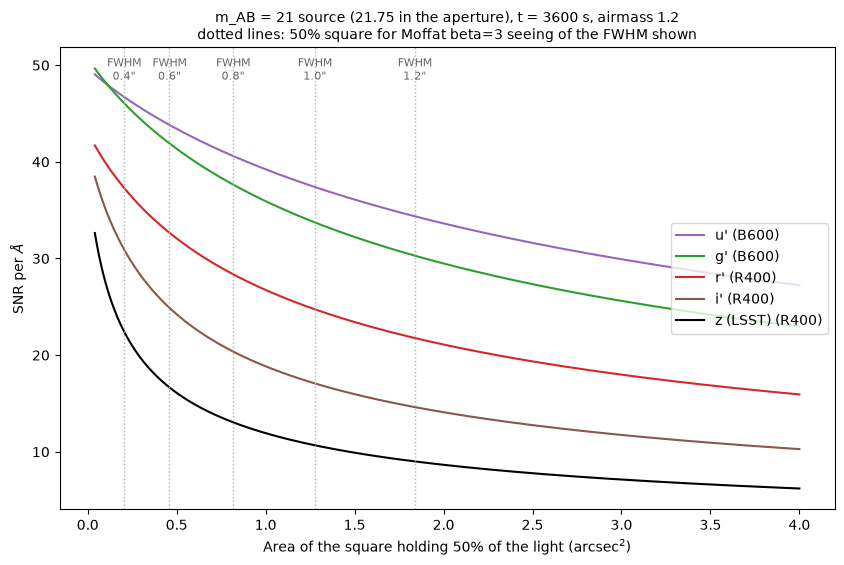

In [13]:
t = 3600.   # s
side = np.linspace(0.2, 2.0, 200)   # arcsec
area = side**2

def snr_per_ang(b, s):
    grating = max((g for g in arms if (b, g) in avg), key=lambda g: avg[(b, g)]['coverage'])
    inst = arms[grating]['inst']
    a = avg[(b, grating)]
    S = 0.5 * src_rate[b] * a['e_tot'] * t
    B = sky_rate[b] * s**2 * a['e_inst'] * t
    npix_per_ang = (s / inst.scale_perp) / inst.Ang_per_pix
    D = npix_per_ang * (inst.readnoise**2 + inst.dark * t)
    return S / np.sqrt(S + B + D), grating, S, B, D

# Side of the 50% square for Moffat seeing (beta = 3) of a given FWHM
fwhms = [0.4, 0.6, 0.8, 1.0, 1.2]
ee50_side = {f: optimize.brentq(lambda s: Moffat.moffat_frac(f, s, s) - 0.5, 0.05, 5) for f in fwhms}
src_mag_ap = src_mag + -2.5 * np.log10(0.5)
fig, ax = plt.subplots(figsize=(10, 6))
for b in bands:
    snr, grating, *_ = snr_per_ang(b, side)
    ax.plot(area, snr, color=colors[b], label=f'{label[b]} ({grating})')
for f, s in ee50_side.items():
    ax.axvline(s**2, color='0.7', ls=':', lw=1)
    ax.text(s**2, 0.98, f'FWHM\n{f}"', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=8, color='0.4')
ax.set_xlabel(r'Area of the square holding 50% of the light (arcsec$^2$)')
ax.set_ylabel(r'SNR per $\AA$')
ax.set_title(f'm_AB = {src_mag:.0f} source ({src_mag_ap:.2f} in the aperture), t = {t:.0f} s, airmass {airmass}\n'
             'dotted lines: 50% square for Moffat beta=3 seeing of the FWHM shown', fontsize=10)
ax.legend(loc='center right')
plt.show()

In [37]:
print(f'50% square side for Moffat beta=3: ' + ', '.join(f'FWHM {f}" -> {s:.3f}"' for f, s in ee50_side.items()))
print()
#print(f"{'band':4} {'arm':5} {'FWHM':>5} {'side':>6} {'S':>8} {'B':>8} {'D':>7} {'SNR/A':>6}")
#for b in bands:
#    for f in (0.4,0.6, 1.0):
#        s = ee50_side[f]
#        snr, grating, S, B, D = snr_per_ang(b, s)
#        print(f'{b:4} {grating:5} {f:5.1f} {s:6.3f} {S:8.1f} {B:8.1f} {D:7.1f} {snr:6.2f}')
print(f"{'band':4} {'arm':5} {'side':>6} {'S':>8} {'B':>8} {'D':>7} {'SNR/A':>6}")
for b in bands:
    for s in (0.346,0.463, 0.568):
        snr, grating, S, B, D = snr_per_ang(b, s)
        print(f'{b:4} {grating:5} {s:6.3f} {S:8.1f} {B:8.1f} {D:7.1f} {snr:6.2f}')


50% square side for Moffat beta=3: FWHM 0.4" -> 0.452", FWHM 0.6" -> 0.678", FWHM 0.8" -> 0.904", FWHM 1.0" -> 1.130", FWHM 1.2" -> 1.356"

band arm     side        S        B       D  SNR/A
u    B600   0.346    394.2    166.8    48.1  15.97
u    B600   0.463    394.2    298.6    64.4  14.32
u    B600   0.568    394.2    449.4    79.0  12.98
g    B600   0.346    409.9    294.0    48.1  14.95
g    B600   0.463    409.9    526.4    64.4  12.96
g    B600   0.568    409.9    792.3    79.0  11.45
r    R400   0.346    294.9    348.0    25.0  11.41
r    R400   0.463    294.9    623.1    33.4   9.56
r    R400   0.568    294.9    937.8    41.0   8.26
i    R400   0.346    272.2    779.8    25.0   8.29
i    R400   0.463    272.2   1396.3    33.4   6.60
i    R400   0.568    272.2   2101.4    41.0   5.54
z    R400   0.346    233.2   1636.2    25.0   5.36
z    R400   0.463    233.2   2929.9    33.4   4.12
z    R400   0.568    233.2   4409.5    41.0   3.41


When the sky dominates the noise ($B \gg S, D$), $\mathrm{SNR} \propto S/\sqrt{B} \propto 1/s$, so SNR $\propto 1/\sqrt{\rm area}$. Halving the seeing FWHM halves the side of the 50% square and so doubles the SNR, which is equivalent to a factor of 4 in exposure time.